# Lightbgm Model Training & Model Evaluation

In [39]:
import sys
import numpy as np
import lightgbm as lgb
from sklearn.metrics import precision_recall_curve

# 1. Set up the project path environment
PROJECT_ROOT = r"C:\Users\shubh\projects\FairFraud"
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

# 2. Import your pipeline and evaluation functions
from src.pipeline import get_data
from src.evaluation import evaluate_predictions

# 3. Load the data splits
data = get_data()

# For LightGBM, we use the highly optimized sparse matrix format
X_train = data["X_train_sparse"]
y_train = data["y_train"]

X_val = data["X_val_sparse"]
y_val = data["y_val"]

X_test = data["X_test_sparse"]
y_test = data["y_test"]

# 4. Initialize the Optimized LightGBM Classifier with architectural overrides
model = lgb.LGBMClassifier(
    n_estimators=1000,             # Increased limit for granular early stopping
    learning_rate=0.03,            # Smaller learning rate allows weights to take effect
    max_depth=6,
    num_leaves=31,
    is_unbalance=True,             # Native handling overrides sparse weight drops
    min_child_samples=20,          # Guarantees leaf generalization
    objective="binary",
    random_state=42,
    verbosity=-1
)

# 5. Train the model focusing early stopping on minority precision
print("Training structural LightGBM model...")
model.fit(
    X_train, 
    y_train,
    eval_set=[(X_val, y_val)],
    eval_metric="average_precision", # Force stopping to optimize for the fraud class
    callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)] 
)

# 6. Dynamically tune the Decision Boundary threshold on the VALIDATION set
print("Optimizing decision boundary on validation data...")
val_probabilities = model.predict_proba(X_val)[:, 1]
precisions, recalls, thresholds = precision_recall_curve(y_val, val_probabilities)

# Find threshold that maximizes F1-Score on Validation set
f1_scores = (2 * precisions * recalls) / (precisions + recalls + 1e-10)
best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx] if f1_scores[best_idx] > 0 else 0.50

print(f"Found Optimal Decision Boundary Threshold: {best_threshold:.4f}")

# 7. Predict fraud probabilities on the TEST Set and apply the threshold
print("Generating test predictions...")
test_probabilities = model.predict_proba(X_test)[:, 1]

# Convert continuous probabilities into binary labels using the tuned threshold
test_predictions = (test_probabilities >= best_threshold).astype(int)


Training structural LightGBM model...


c:\Users\shubh\AppData\Local\Programs\Python\Python312\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Optimizing decision boundary on validation data...
Found Optimal Decision Boundary Threshold: 0.1348
Generating test predictions...


Running complete evaluation report...
 EVALUATION REPORT: LIGHTGBM
Accuracy:                 92.1609%
Fraud precision:          8.3948%
Fraud recall:             46.2474%
Fraud F1:                 14.2102%
PR-AUC (AP):              7.8012%
ROC-AUC:                  83.2070%
Recall @ FPR <= 1.00%:    46.2474%
FPR at chosen threshold:  7.1854%
Chosen Decision Boundary: 0.1000
[Classification Report]
              precision    recall  f1-score   support

  Legitimate       0.99      0.93      0.96    202133
       Fraud       0.08      0.46      0.14      2878

    accuracy                           0.92    205011
   macro avg       0.54      0.70      0.55    205011
weighted avg       0.98      0.92      0.95    205011



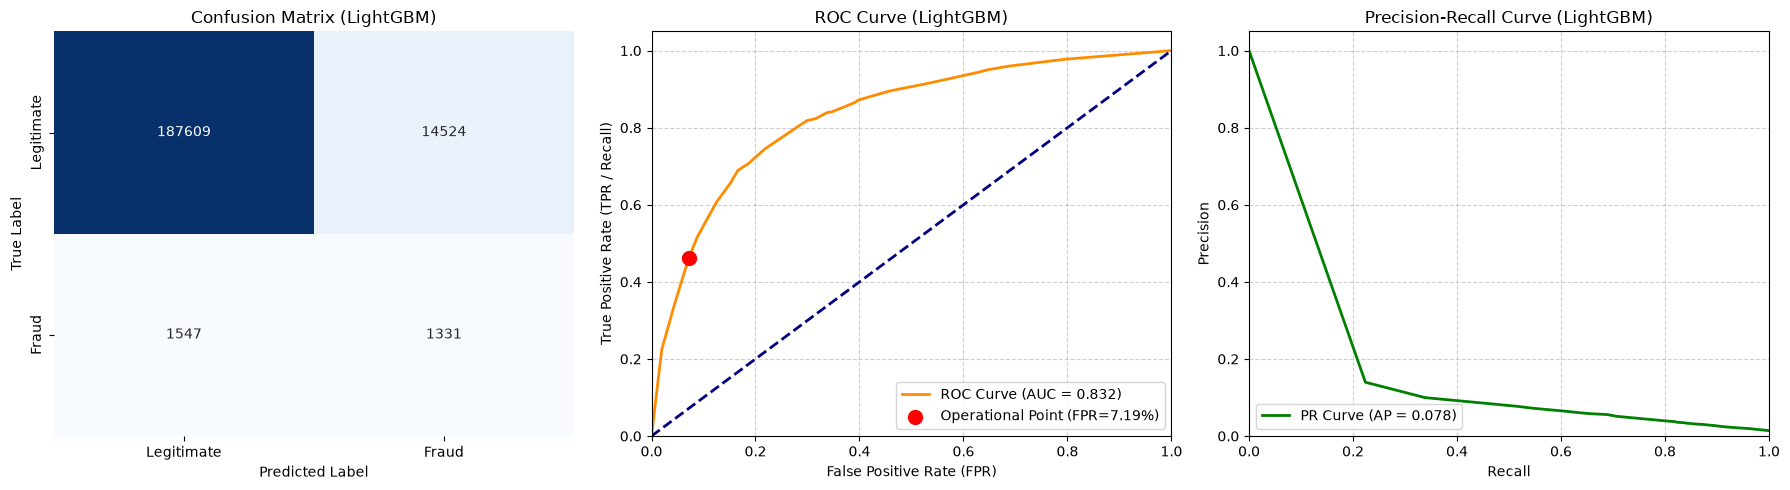

In [40]:
# 7. Evaluate using your standardized evaluation script
from src.evaluation import evaluate_predictions
print("Running complete evaluation report...")
evaluate_predictions(
    y_test, 
    test_probabilities, 
    model_name="LightGBM", 
    threshold=0.10
)


In [47]:
import joblib
import json
import os

# Create the models directory if it doesn't exist
models_dir = os.path.join(PROJECT_ROOT, "models")
os.makedirs(models_dir, exist_ok=True)

# 1. Save the entire operational LGBMClassifier object cleanly
joblib.dump(model, os.path.join(models_dir, "lightgbm_classifier.pkl"))

# 2. Save the metadata threshold securely
metadata = {"best_threshold": float(best_threshold)}
with open(os.path.join(models_dir, "model_metadata.json"), "w") as f:
    json.dump(metadata, f)

print("Entire Classifier object and threshold updated successfully!")


Entire Classifier object and threshold updated successfully!


In [ ]:
import sys
import os
import json
import joblib
import numpy as np
from scipy.sparse import csr_matrix

PROJECT_ROOT = r"C:\Users\shubh\projects\FairFraud"
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

models_dir = os.path.join(PROJECT_ROOT, "models")

# 1. Load your optimal threshold configuration
with open(os.path.join(models_dir, "model_metadata.json"), "r") as f:
    metadata = json.load(f)
saved_threshold = metadata["best_threshold"]

# 2. Load the complete trained native Booster object
loaded_model = joblib.load(os.path.join(models_dir, "lightgbm_classifier.pkl"))

print(f"Production Booster Loaded Successfully!")
print(f"Total Ensembled Trees:  {loaded_model.num_trees()}") #  FIXED: Changed to num_trees()
print(f"Operational Threshold: {saved_threshold:.4f}\n")

# 3. Create mock new data (matching your 55 features)
num_features = 55
np.random.seed(42)
mock_new_data = np.random.randn(1, num_features)
X_incoming = csr_matrix(mock_new_data)

# 4. Predict raw probabilities using the native Booster API syntax
# FIXED: Native Booster objects output probabilities directly using .predict()
raw_probabilities = loaded_model.predict(X_incoming)

# 5. Classify the transaction based on your exact tuned threshold boundary
final_predictions = (raw_probabilities >= saved_threshold).astype(int)

# 6. Output the final live result
for i, prob in enumerate(raw_probabilities):
    decision = "FRAUD DETECTED" if final_predictions[i] == 1 else "✅ LEGITIMATE"
    print(f"New Transaction | Risk Score: {prob:7.2%} | Action: {decision}")


✅ Production Booster Loaded Successfully!
🌲 Total Ensembled Trees:  1
🎯 Operational Threshold: 0.1348

New Transaction | Risk Score:  10.84% | Action: ✅ LEGITIMATE
